In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset location relative to the Stage 2 notebook directory
DATA_PATH = Path(
    "../../../data/coconut_health/stage2/data/"
    "cococare_stage2_outputs/stage2_combined_scenarios.csv"
)

df = pd.read_csv(DATA_PATH)

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "scenario"]).reset_index(drop=True)

print("=" * 65)
print("COCOCARE STAGE 2 — DATASET INSPECTION")
print("=" * 65)

print("\nShape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nScenario distribution:")
print(df["scenario"].value_counts())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nStress class distribution:")
print(pd.crosstab(
    df["scenario"],
    df["water_stress_rule_derived"]
))

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nDuplicate scenario-date records:")
print(df.duplicated(["date", "scenario"]).sum())

print("\nSample records:")
display(df.head())


COCOCARE STAGE 2 — DATASET INSPECTION

Shape: (1094, 34)

Columns:
['date', 'rainfall_mm', 'tmax_c', 'tmin_c', 'solar_radiation_mj_m2_day', 'relative_humidity_pct', 'wind_speed_m_s', 'weather_source', 'weather_source_url', 'et0_mm_day', 'etc_potential_mm_day_modelled', 'scenario', 'simulated_palm_age_months', 'effective_rainfall_mm_modelled', 'runoff_mm_modelled', 'irrigation_litres_per_palm_simulated', 'effective_wetted_area_m2_assumed', 'irrigation_mm_simulated', 'actual_et_mm_day_modelled', 'drainage_mm_modelled', 'soil_water_storage_mm_modelled', 'depletion_fraction_modelled', 'soil_moisture_vwc_pct_simulated', 'water_stress_rule_derived', 'recommended_action_simulated', 'soil_temperature_c', 'soil_temperature_status', 'model_status', 'stress_label_status', 'location', 'latitude', 'longitude', 'variety', 'data_class']

Scenario distribution:
scenario
tnau_guided_irrigation    547
weather_only              547
Name: count, dtype: int64

Date range:
2023-01-01 00:00:00 to 2024-06-30 

,date,rainfall_mm,tmax_c,tmin_c,solar_radiation_mj_m2_day,relative_humidity_pct,wind_speed_m_s,weather_source,weather_source_url,et0_mm_day,...,recommended_action_simulated,soil_temperature_c,soil_temperature_status,model_status,stress_label_status,location,latitude,longitude,variety,data_class
0,2023-01-01,0.0,27.36,15.54,21.15,77.68,1.09,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...,3.606898,...,recheck_soil_and_weather,NaN,not_modelled_no_defensible_method_or_measurements,prototype_provisional_parameters_not_field_val...,rule_derived_not_ground_truth,"Pollachi, Tamil Nadu, India",10.746,77.0976,East Coast Tall,NASA_POWER_weather_plus_modelled_outputs
1,2023-01-01,0.0,27.36,15.54,21.15,77.68,1.09,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...,3.606898,...,recheck_soil_and_weather,NaN,not_modelled_no_defensible_method_or_measurements,prototype_provisional_parameters_not_field_val...,rule_derived_not_ground_truth,"Pollachi, Tamil Nadu, India",10.746,77.0976,East Coast Tall,NASA_POWER_weather_plus_modelled_outputs
2,2023-01-02,0.0,26.75,15.95,20.19,78.70,1.39,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...,3.497985,...,recheck_soil_and_weather,NaN,not_modelled_no_defensible_method_or_measurements,prototype_provisional_parameters_not_field_val...,rule_derived_not_ground_truth,"Pollachi, Tamil Nadu, India",10.746,77.0976,East Coast Tall,NASA_POWER_weather_plus_modelled_outputs
3,2023-01-02,0.0,26.75,15.95,20.19,78.70,1.39,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...,3.497985,...,recheck_soil_and_weather,NaN,not_modelled_no_defensible_method_or_measurements,prototype_provisional_parameters_not_field_val...,rule_derived_not_ground_truth,"Pollachi, Tamil Nadu, India",10.746,77.0976,East Coast Tall,NASA_POWER_weather_plus_modelled_outputs
4,2023-01-03,0.0,26.59,14.57,19.71,80.45,1.36,NASA_POWER_daily_point,https://power.larc.nasa.gov/docs/services/api/...,3.338542,...,recheck_soil_and_weather,NaN,not_modelled_no_defensible_method_or_measurements,prototype_provisional_parameters_not_field_val...,rule_derived_not_ground_truth,"Pollachi, Tamil Nadu, India",10.746,77.0976,East Coast Tall,NASA_POWER_weather_plus_modelled_outputs


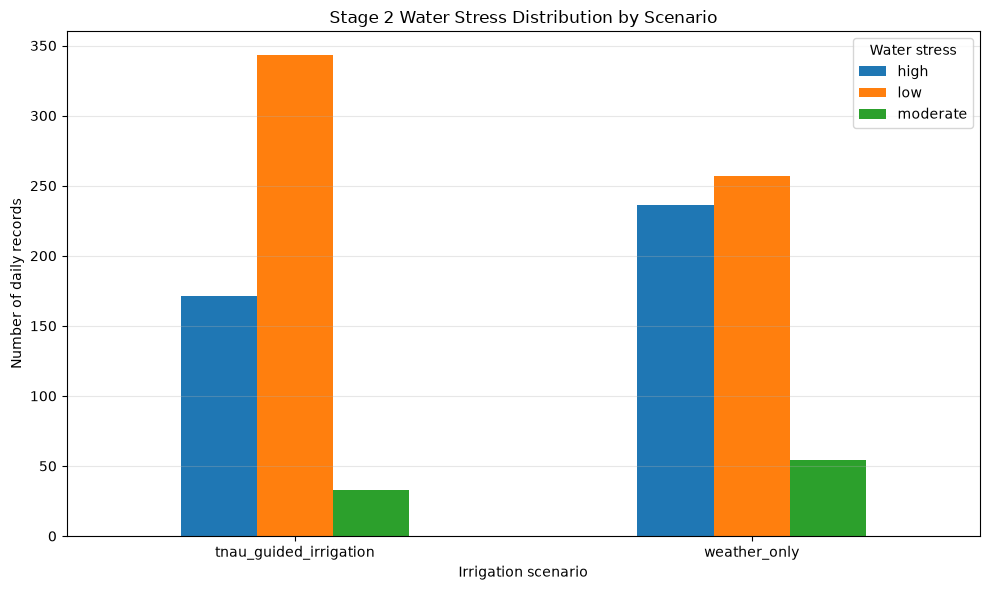

In [2]:

# ==========================================
# STAGE 2 CLASS DISTRIBUTION
# ==========================================

OUTPUT_DIR = Path(
    "../../../results/coconut_health/stage2_ml"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

class_counts = pd.crosstab(
    df["scenario"],
    df["water_stress_rule_derived"]
)

class_counts.to_csv(
    TABLE_DIR / "stage2_class_distribution.csv"
)

ax = class_counts.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("Stage 2 Water Stress Distribution by Scenario")
ax.set_xlabel("Irrigation scenario")
ax.set_ylabel("Number of daily records")
ax.legend(title="Water stress")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "stage2_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [3]:

# ==========================================
# STAGE 2 — FEATURE LEAKAGE AUDIT
# ==========================================

TARGET = "water_stress_rule_derived"
GROUP = "scenario"
DATE = "date"

# Features available from weather and scenario inputs
BASE_FEATURES = [
    "rainfall_mm",
    "tmax_c",
    "tmin_c",
    "solar_radiation_mj_m2_day",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "et0_mm_day",
    "etc_potential_mm_day_modelled",
    "simulated_palm_age_months",
    "scenario",
]

# Current-day prediction can use the scheduled irrigation input
CURRENT_DAY_FEATURES = BASE_FEATURES + [
    "irrigation_litres_per_palm_simulated"
]

# Explicitly prohibited target-derived features
LEAKAGE_FEATURES = [
    "effective_rainfall_mm_modelled",
    "runoff_mm_modelled",
    "irrigation_mm_simulated",
    "actual_et_mm_day_modelled",
    "drainage_mm_modelled",
    "soil_water_storage_mm_modelled",
    "depletion_fraction_modelled",
    "soil_moisture_vwc_pct_simulated",
    "recommended_action_simulated",
]

print("Current-day feature count:", len(CURRENT_DAY_FEATURES))
print("\nCurrent-day features:")
for feature in CURRENT_DAY_FEATURES:
    print("  ", feature)

print("\nLeakage audit:")
for feature in LEAKAGE_FEATURES:
    print("  EXCLUDED:", feature)

# Verify all selected features exist
missing_features = [
    col for col in CURRENT_DAY_FEATURES
    if col not in df.columns
]

assert not missing_features, (
    f"Missing feature columns: {missing_features}"
)

# Ensure target is not accidentally included
assert TARGET not in CURRENT_DAY_FEATURES
assert not set(CURRENT_DAY_FEATURES).intersection(
    LEAKAGE_FEATURES
)

print("\nFeature leakage audit passed.")


Current-day feature count: 11

Current-day features:
   rainfall_mm
   tmax_c
   tmin_c
   solar_radiation_mj_m2_day
   relative_humidity_pct
   wind_speed_m_s
   et0_mm_day
   etc_potential_mm_day_modelled
   simulated_palm_age_months
   scenario
   irrigation_litres_per_palm_simulated

Leakage audit:
  EXCLUDED: effective_rainfall_mm_modelled
  EXCLUDED: runoff_mm_modelled
  EXCLUDED: irrigation_mm_simulated
  EXCLUDED: actual_et_mm_day_modelled
  EXCLUDED: drainage_mm_modelled
  EXCLUDED: soil_water_storage_mm_modelled
  EXCLUDED: depletion_fraction_modelled
  EXCLUDED: soil_moisture_vwc_pct_simulated
  EXCLUDED: recommended_action_simulated

Feature leakage audit passed.


In [4]:

# ==========================================
# STAGE 2 — BUILD EXPERIMENT DATASETS
# ==========================================

from sklearn.model_selection import GroupShuffleSplit

TARGET = "water_stress_rule_derived"

WEATHER_BASE = [
    "rainfall_mm",
    "tmax_c",
    "tmin_c",
    "solar_radiation_mj_m2_day",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "et0_mm_day",
]

# Three feature configurations
FEATURE_GROUPS = {
    "weather_baseline": WEATHER_BASE,

    "scenario_aware": WEATHER_BASE + [
        "scenario"
    ],

    "intervention_aware": WEATHER_BASE + [
        "scenario",
        "irrigation_litres_per_palm_simulated"
    ],
}

# Check required columns
for group_name, features in FEATURE_GROUPS.items():
    missing = [c for c in features if c not in df.columns]
    assert not missing, f"{group_name}: missing {missing}"

# Sort within each scenario before shifting
df = df.sort_values(
    ["scenario", "date"]
).reset_index(drop=True)

# Current-day target
df["target_current"] = df[TARGET]
df["target_date_current"] = df["date"]

# Next-day target: shift independently within each scenario
df["target_next_day"] = (
    df.groupby("scenario")[TARGET].shift(-1)
)

df["target_date_next"] = (
    df.groupby("scenario")["date"].shift(-1)
)

# Verify next-day date alignment
date_difference = (
    df["target_date_next"] - df["date"]
).dropna()

assert (date_difference == pd.Timedelta(days=1)).all(), (
    "Unexpected date gap found in next-day target alignment."
)

# Build separate datasets
current_data = df.dropna(
    subset=WEATHER_BASE + [
        "target_current",
        "target_date_current"
    ]
).copy()

next_data = df.dropna(
    subset=WEATHER_BASE + [
        "target_next_day",
        "target_date_next"
    ]
).copy()

print("CURRENT-DAY DATA")
print("Shape:", current_data.shape)
print(current_data["scenario"].value_counts())
print(current_data["target_current"].value_counts())

print("\nNEXT-DAY DATA")
print("Shape:", next_data.shape)
print(next_data["scenario"].value_counts())
print(next_data["target_next_day"].value_counts())

print("\nNext-day date alignment passed.")


CURRENT-DAY DATA
Shape: (1094, 38)
scenario
tnau_guided_irrigation    547
weather_only              547
Name: count, dtype: int64
target_current
low         600
high        407
moderate     87
Name: count, dtype: int64

NEXT-DAY DATA
Shape: (1092, 38)
scenario
tnau_guided_irrigation    546
weather_only              546
Name: count, dtype: int64
target_next_day
low         600
high        407
moderate     85
Name: count, dtype: int64

Next-day date alignment passed.


In [5]:

# ==========================================
# DATE-GROUPED SPLITTING
# ==========================================

def grouped_random_split(data, target_date_col):
    """
    Approximate 70/15/15 random benchmark.
    All rows from the same date remain together.
    """

    data = data.copy().reset_index(drop=True)
    groups = data[target_date_col]

    # First: 70% training, 30% temporary
    first_split = GroupShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=42
    )

    train_idx, temp_idx = next(
        first_split.split(data, groups=groups)
    )

    train = data.iloc[train_idx].copy()
    temp = data.iloc[temp_idx].copy()

    # Split remaining dates equally
    second_split = GroupShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=42
    )

    val_idx, test_idx = next(
        second_split.split(
            temp,
            groups=temp[target_date_col]
        )
    )

    val = temp.iloc[val_idx].copy()
    test = temp.iloc[test_idx].copy()

    return train, val, test


def chronological_group_split(data, target_date_col):
    """
    70/15/15 chronological split by unique target dates.
    Both scenarios for a date stay together.
    """

    data = data.sort_values(target_date_col).copy()

    unique_dates = np.sort(
        data[target_date_col].dropna().unique()
    )

    n_dates = len(unique_dates)

    train_end = int(n_dates * 0.70)
    val_end = int(n_dates * 0.85)

    train_dates = set(unique_dates[:train_end])
    val_dates = set(unique_dates[train_end:val_end])
    test_dates = set(unique_dates[val_end:])

    train = data[
        data[target_date_col].isin(train_dates)
    ].copy()

    val = data[
        data[target_date_col].isin(val_dates)
    ].copy()

    test = data[
        data[target_date_col].isin(test_dates)
    ].copy()

    return train, val, test


def validate_splits(name, splits, target_col, date_col):

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    date_sets = []

    for split_name, part in zip(
        ["TRAIN", "VALIDATION", "TEST"],
        splits
    ):
        dates = set(part[date_col].unique())
        date_sets.append(dates)

        print(f"\n{split_name}")
        print("Records:", len(part))
        print("Unique dates:", len(dates))
        print("Date range:",
              part[date_col].min(),
              "to",
              part[date_col].max())

        print("Scenario counts:")
        print(part["scenario"].value_counts())

        print("Stress classes:")
        print(
            pd.crosstab(
                part["scenario"],
                part[target_col]
            )
        )

    # No date may occur in more than one split
    assert date_sets[0].isdisjoint(date_sets[1])
    assert date_sets[0].isdisjoint(date_sets[2])
    assert date_sets[1].isdisjoint(date_sets[2])

    print("\nNo date overlap between splits.")


# Current-day splits
current_random = grouped_random_split(
    current_data,
    "target_date_current"
)

current_chrono = chronological_group_split(
    current_data,
    "target_date_current"
)

# Next-day splits
next_random = grouped_random_split(
    next_data,
    "target_date_next"
)

next_chrono = chronological_group_split(
    next_data,
    "target_date_next"
)

# Validate all four
validate_splits(
    "CURRENT-DAY RANDOM",
    current_random,
    "target_current",
    "target_date_current"
)

validate_splits(
    "CURRENT-DAY CHRONOLOGICAL",
    current_chrono,
    "target_current",
    "target_date_current"
)

validate_splits(
    "NEXT-DAY RANDOM",
    next_random,
    "target_next_day",
    "target_date_next"
)

validate_splits(
    "NEXT-DAY CHRONOLOGICAL",
    next_chrono,
    "target_next_day",
    "target_date_next"
)



CURRENT-DAY RANDOM

TRAIN
Records: 764
Unique dates: 382
Date range: 2023-01-02 00:00:00 to 2024-06-29 00:00:00
Scenario counts:
scenario
tnau_guided_irrigation    382
weather_only              382
Name: count, dtype: int64
Stress classes:
target_current          high  low  moderate
scenario                                   
tnau_guided_irrigation   128  230        24
weather_only             168  172        42

VALIDATION
Records: 164
Unique dates: 82
Date range: 2023-01-03 00:00:00 to 2024-06-30 00:00:00
Scenario counts:
scenario
tnau_guided_irrigation    82
weather_only              82
Name: count, dtype: int64
Stress classes:
target_current          high  low  moderate
scenario                                   
tnau_guided_irrigation    17   60         5
weather_only              27   47         8

TEST
Records: 166
Unique dates: 83
Date range: 2023-01-01 00:00:00 to 2024-06-24 00:00:00
Scenario counts:
scenario
tnau_guided_irrigation    83
weather_only              83
Name: cou